<a href="https://colab.research.google.com/github/serin19538-jpg/MS49900_ADV/blob/main/Hand-on-session5/2026_2_Hands_on_session5_advanced.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced Session: Electrolyte Conductivity Challenge
AI for Materials Science — Hands-on session 5 (optional)

A one-week, Kaggle-style challenge: predict the **ionic conductivity k (mS/cm)** of liquid electrolytes
from their salt, concentration, solvent mixture and temperature. You get the training table with labels, train
a scikit-learn model in this notebook, and upload the trained model as one file, `model.joblib`.

**Site:** https://hos5.tail1aab16.ts.net

- Task: predict ionic conductivity k (mS/cm) of liquid electrolytes on the hidden test rows. Metric: RMSLE (lower is better).
- Open: 2026-11-02 17:30 KST. Deadline: 2026-11-08 23:59 KST. Private results: 2026-11-09 09:00 KST.
- Submission: upload model.joblib, your trained scikit-learn model or pipeline (XGBoost and LightGBM through their scikit-learn classes) saved with joblib.dump. The server loads it and calls predict(test), which must return one predicted k for each test row, in the order of the test rows; test has the feature columns of train, without k.
- Versions: save the model with scikit-learn==1.9.1, xgboost==3.4.1, lightgbm==4.7.0; a model saved with another scikit-learn version is rejected. File size: at most 200 MB. Loading and predicting must finish within 5 minutes, without internet access.
- Limit: 5 scored submissions per student per KST day; runs that fail do not count, up to 10 failed runs a day. The upload time decides whether a submission made the deadline.
- Identity: your student ID and the 6-digit access code sent to you on KLMS. Only your nickname is shown.
- Final ranking uses the private RMSLE of each student's best public submission.
- Too many failed logins trigger a 15-minute cool-down; 30 failures in a day lock that ID for the day.
- Locked? Contact the TA; a server restart clears locks.

---

Run the cells one at a time from the top. Later cells reuse variables created in earlier ones, so skipping ahead gives you a "name is not defined" error. Lines starting with `##` inside the code are comments written for you; Python does not run them.

## 0. Setup

### 0-1. Install the server's library versions
The server loads your model with scikit-learn 1.9.1, XGBoost 3.4.1 and LightGBM 4.7.0. A saved model
opens reliably only with the versions it was saved with, and the server rejects a model saved with another
scikit-learn version, so the cell below installs exactly these versions before anything else is imported. Run
it first. If it reports other versions, choose Runtime ▸ Restart session and run it again. No GPU is needed.

In [77]:
!pip install -q scikit-learn==1.9.1 xgboost==3.4.1 lightgbm==4.7.0   ## the versions the server loads models with
import sklearn, xgboost, lightgbm
print("scikit-learn", sklearn.__version__, " xgboost", xgboost.__version__, " lightgbm", lightgbm.__version__)
assert (sklearn.__version__, xgboost.__version__, lightgbm.__version__) == ("1.9.1", "3.4.1", "4.7.0"), \
    "other versions are loaded: choose Runtime > Restart session, then run this cell again"

scikit-learn 1.9.1  xgboost 3.4.1  lightgbm 4.7.0


### 0-2. Download the course material

In [78]:
!git clone https://github.com/kwongibaek/MS49900-AI4M.git

fatal: destination path 'MS49900-AI4M' already exists and is not an empty directory.


### 0-3. Import the libraries

In [79]:
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GroupKFold

np.random.seed(0)

### 0-4. Set the file paths

In [80]:
DATA_DIR = Path("MS49900-AI4M/Data")
OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)
print("Data folder exists:", DATA_DIR.exists())

Data folder exists: True


## A. The data

### A-1. Load the training table
`train` has the target column `k` and the feature columns. The test rows stay on the server: your
model's `predict` receives them as a table with the same feature columns and no `k`.

In [81]:
train = pd.read_csv(DATA_DIR / "train_set.csv")
print("train:", train.shape)
train.head()

train: (10810, 44)


,k,T,c,salt,c units,solvent ratio type,EC,PC,DMC,EMC,...,Ethylbenzene,Ethylmonoglyme,Benzene,g-Butyrolactone,Cumene,Propylsulfone,Pseudocumeme,TEOS,m-Xylene,o-Xylene
0,0.160643,333.235034,1.0,LiPF6,mol/kg,w,0.33,0.0,0.33,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0
1,0.150856,322.764924,1.0,LiPF6,mol/kg,w,0.33,0.0,0.33,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0
2,0.141666,313.801722,1.0,LiPF6,mol/kg,w,0.33,0.0,0.33,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0
3,0.132277,303.681806,1.0,LiPF6,mol/kg,w,0.33,0.0,0.33,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0
4,0.119348,293.049793,1.0,LiPF6,mol/kg,w,0.33,0.0,0.33,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0


### A-2. What the columns mean
- `T` — temperature in kelvin.
- `c` — lithium-salt concentration, in the unit given by `c units` (mol/kg or mol/L).
- `salt` — the lithium salt (LiPF6, LiBF4, LiBOB, ...).
- `solvent ratio type` — whether the solvent columns are weight (`w`), volume (`v`) or mole (`mol`) fractions.
- 38 solvent columns (EC, PC, DMC, EMC, DEC, DME, ...) — the fraction of each solvent; each row sums to 1.
- `k` — ionic conductivity in mS/cm (train only). Most values are below 15 mS/cm.

The test rows are new formulations: no salt/solvent/concentration combination in the test set appears in
`train`, so you predict new mixtures, not new temperatures of a mixture you already know.

During the week the leaderboard shows your score on 30% of the test formulations (public). The final ranking
uses the other 70% (private), revealed after the deadline.

### A-3. The target distribution

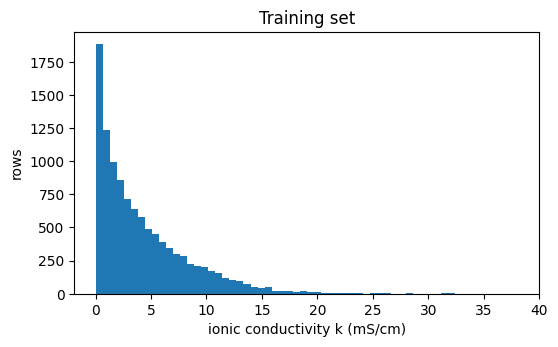

count    10810.000
mean         4.196
std          4.157
min          0.000
25%          1.039
50%          2.945
75%          6.170
max         38.100
Name: k, dtype: float64


In [82]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(train["k"], bins=60)
ax.set_xlabel("ionic conductivity k (mS/cm)"); ax.set_ylabel("rows")
ax.set_title("Training set")
fig.savefig(OUTPUT / "A3_k_hist.png", dpi=150, bbox_inches="tight")
plt.show()
print(train["k"].describe().round(3))

## B. Features
Three columns are text (categories) and the rest are numbers. Most models need numbers only, so how you turn the
text columns into numbers is part of your model: fit that step on the training rows only, and make sure a
category that appears only in the test rows does not crash it.

In [83]:
CATEGORICAL = ["salt", "c units", "solvent ratio type"]
NUMERIC = [c for c in train.columns if c not in CATEGORICAL + ["k"]]
X, y = train.drop(columns="k"), train["k"]
print(len(NUMERIC), "numeric columns +", len(CATEGORICAL), "categorical columns")

40 numeric columns + 3 categorical columns


In [84]:
## [B-2] feature 감사 (데이터만, 모델 없음)
SOLVENTS = [c for c in NUMERIC if c not in ("T", "c")]
S = X[SOLVENTS]

print("== 1. 용매 분율 합 (1이 아니면 누락 성분 = 숨은 변수 가능성) ==")
ssum = S.sum(axis=1); dev = (ssum - 1).abs()
print(ssum.describe(percentiles=[.001, .01, .05, .5, .95, .99, .999]).round(4).to_string())
print("|합-1|>0.01 행:", int((dev > 0.01).sum()), "| >0.05:", int((dev > 0.05).sum()))
if (dev > 0.01).any():
    print(pd.crosstab(dev > 0.01, X["c units"]).to_string())
    print(X.loc[dev > 0.01, ["salt", "c units", "solvent ratio type"]].value_counts().head(10).to_string())

print("\n== 2. 모든 feature(T 포함)가 같은 행 → 순수 라벨 노이즈 ==")
dupF = X.duplicated(keep=False)
print("행 수:", int(dupF.sum()))
if dupF.any():
    sp = train[dupF].groupby(list(X.columns), dropna=False)["k"].agg(["size", "min", "max"])
    print("그룹 수:", len(sp), "| max/min 비율:", (sp["max"] / sp["min"].clip(lower=1e-6)).describe().round(3).to_dict())

print("\n== 3. 단위별 T 격자 / c 정밀도 ==")
for u, g in X.groupby("c units"):
    nd = g["c"].astype(str).str.split(".").str[1].str.len()
    print(f"{u}: unique T {g['T'].nunique()} | T 상위 {g['T'].round(2).value_counts().head(8).to_dict()}")
    print(f"   c 소수 자릿수 분포 {nd.value_counts().sort_index().to_dict()}")

print("\n== 4. 용매 조합 패턴 x 단위 (상위 20) ==")
pat = (S > 0).apply(lambda r: "+".join(r.index[r.values]), axis=1)
print(pd.crosstab(pat, X["c units"]).assign(tot=lambda t: t.sum(1)).sort_values("tot", ascending=False).head(20).to_string())

print("\n== 5. salt x 단위 ==")
print(pd.crosstab(X["salt"], X["c units"]).to_string())

== 1. 용매 분율 합 (1이 아니면 누락 성분 = 숨은 변수 가능성) ==
count    10810.0000
mean         1.0000
std          0.0005
min          0.9900
0.1%         0.9900
1%           1.0000
5%           1.0000
50%          1.0000
95%          1.0000
99%          1.0000
99.9%        1.0000
max          1.0000
|합-1|>0.01 행: 31 | >0.05: 0
c units  mol/kg  mol/l
row_0                 
False      8468   2311
True         23      8
salt      c units  solvent ratio type
LiPF6     mol/kg   w                     12
LiBF4     mol/kg   w                     11
LiCF3SO3  mol/l    v                      3
LiClO4    mol/l    v                      3
LiTFSI    mol/l    v                      2

== 2. 모든 feature(T 포함)가 같은 행 → 순수 라벨 노이즈 ==
행 수: 57
그룹 수: 28 | max/min 비율: {'count': 28.0, 'mean': 1.013, 'std': 0.024, 'min': 1.0, '25%': 1.003, '50%': 1.004, '75%': 1.01, 'max': 1.115}

== 3. 단위별 T 격자 / c 정밀도 ==
mol/kg: unique T 56 | T 상위 {332.15: 685, 312.45: 675, 322.35: 672, 263.15: 671, 302.55: 659, 292.65: 642, 272.95: 634, 282.

## C. Validate the way the leaderboard scores

### C-1. Formulations as groups
The leaderboard's hidden split keeps every row of one formulation (salt, concentration, unit, ratio type and
the 38 solvent fractions) on one side. Validate the same way, or your local score will be too optimistic.

In [85]:
KEY = ["salt", "c", "c units", "solvent ratio type"] + [c for c in NUMERIC if c not in ("T", "c")]
groups = train[KEY].astype(str).agg("|".join, axis=1)
print(groups.nunique(), "formulations in", len(train), "training rows")

4884 formulations in 10810 training rows


### C-2. A validation tool
Which model to use is your decision: a decision tree, a random forest, an MLP (scikit-learn's `MLPRegressor`),
XGBoost or LightGBM through their scikit-learn classes `XGBRegressor` and `LGBMRegressor`, or any other
scikit-learn model. Only scikit-learn models can be submitted. `grouped_rmsle(make_model, X, y, groups)` scores
a model the way the leaderboard does: 5 folds, every formulation on one side, RMSLE (the RMSE of ln(1 + k),
negative predictions counted as 0) averaged over the folds. On this scale the few large k values no longer
dominate the score, so low-conductivity electrolytes count too. `make_model` is a function that returns a new,
untrained model with `fit(X, y)` and `predict(X)`, for example `lambda: make_pipeline(...)`: every fold builds its own
model, so nothing learned on one fold leaks into the score of another. Put the text-column encoding inside the
model (for example a scikit-learn pipeline) so that every fold fits it on its own training rows.

In [86]:
def grouped_rmsle(make_model, X, y, groups, n_splits=5):
    scores = []
    for fit_idx, val_idx in GroupKFold(n_splits=n_splits).split(X, y, groups=groups):
        model = make_model()   ## a new, untrained model for every fold
        model.fit(X.iloc[fit_idx], y.iloc[fit_idx])
        pred = np.clip(model.predict(X.iloc[val_idx]), 0, None)
        scores.append(np.sqrt(mean_squared_error(np.log1p(y.iloc[val_idx]), np.log1p(pred))))
    return float(np.mean(scores)), float(np.std(scores))

### C-3. Practice 1
Choose two or more candidate models, build each one with its own text-column encoding, and compare them with
`grouped_rmsle`. Then tune the best one with the same function, never with the leaderboard. Your best one
becomes the `make_model` that D-1 trains and saves.

In [87]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

SOLVENTS = [c for c in NUMERIC if c not in ("T", "c")]

## Solvent descriptors (approx. literature values, 25 C): dielectric const, viscosity (cP), MW, density, donor number
SOLV = {
 "EC": (89.8, 1.90, 88.06, 1.32, 16.4), "PC": (64.9, 2.53, 102.09, 1.20, 15.1),
 "DMC": (3.1, 0.59, 90.08, 1.07, 17.2), "EMC": (2.96, 0.65, 104.10, 1.01, 17.0),
 "DEC": (2.8, 0.75, 118.13, 0.97, 16.0), "DME": (7.2, 0.46, 90.12, 0.87, 20.0),
 "DMSO": (46.5, 1.99, 78.13, 1.10, 29.8), "AN": (35.9, 0.34, 41.05, 0.78, 14.1),
 "MOEMC": (6.0, 1.10, 134.13, 1.08, 16.0), "TFP": (7.0, 2.30, 344.07, 1.59, 5.0),
 "EA": (6.0, 0.43, 88.11, 0.90, 17.1), "MA": (6.7, 0.36, 74.08, 0.93, 16.5),
 "FEC": (78.4, 4.10, 106.05, 1.45, 9.0), "DOL": (7.1, 0.59, 74.08, 1.06, 18.0),
 "2-MeTHF": (6.97, 0.46, 86.13, 0.85, 18.0), "DMM": (2.7, 0.33, 76.09, 0.86, 15.0),
 "Freon 11": (2.3, 0.42, 137.37, 1.49, 0.1), "Methylene chloride": (8.9, 0.41, 84.93, 1.33, 1.0),
 "THF": (7.6, 0.46, 72.11, 0.89, 20.0), "Toluene": (2.38, 0.56, 92.14, 0.87, 0.1),
 "Sulfolane": (43.3, 10.3, 120.17, 1.26, 14.8), "2-Glyme": (7.4, 0.99, 134.17, 0.94, 19.5),
 "3-Glyme": (7.5, 1.89, 178.23, 0.99, 14.0), "4-Glyme": (7.8, 3.39, 222.28, 1.01, 16.6),
 "3-Me-2-Oxazolidinone": (77.5, 2.45, 101.10, 1.17, 16.0), "3-MeSulfolane": (29.4, 11.0, 134.20, 1.20, 14.0),
 "Ethyldiglyme": (5.7, 1.40, 162.23, 0.91, 18.0), "DMF": (36.7, 0.80, 73.09, 0.94, 26.6),
 "Ethylbenzene": (2.4, 0.64, 106.17, 0.87, 0.1), "Ethylmonoglyme": (5.1, 0.65, 118.17, 0.84, 19.0),
 "Benzene": (2.28, 0.60, 78.11, 0.88, 0.1), "g-Butyrolactone": (39.0, 1.73, 86.09, 1.13, 18.0),
 "Cumene": (2.38, 0.74, 120.19, 0.86, 0.1), "Propylsulfone": (32.0, 4.00, 150.24, 1.03, 14.0),
 "Pseudocumeme": (2.38, 0.89, 120.19, 0.88, 0.1), "TEOS": (2.5, 0.70, 208.33, 0.93, 5.0),
 "m-Xylene": (2.37, 0.58, 106.17, 0.86, 0.1), "o-Xylene": (2.57, 0.76, 106.17, 0.88, 0.1),
}
## Salt descriptors: MW, approx. anion volume (A^3), rough dissociation score
SALT = {
 "LiPF6": (151.9, 69, 0.8), "LiBOB": (193.8, 120, 0.6), "LiBF4": (93.7, 53, 0.4),
 "LiAsF6": (195.9, 72, 0.85), "LiBPFPB": (671.0, 330, 0.7), "LiCF3SO3": (156.0, 80, 0.2),
 "LiClO4": (106.4, 55, 0.6), "LiTFSI": (287.1, 150, 0.9), "LiN(CF3SO2)2": (287.1, 150, 0.9),
 "LiBMB": (208.0, 140, 0.5), "LiFSI": (187.1, 100, 0.9), "LiTDI": (192.0, 110, 0.75),
 "LiPDI": (242.0, 130, 0.75),
}

## Mixture-averaged solvent properties, built only from numpy functions (so the pickle loads on the server):
## F @ W1 -> weighted sums, log, @ W2 -> log(sum prop) - log(sum weight) = log of the mixture average.
## Three averaging bases (fractions read as mol, w, v) because the ratio type differs per row.
P = np.array([SOLV[s] for s in SOLVENTS], float)
eps, eta, mw, rho, dn = P.T
props = np.c_[eps, np.log(eta) + 3, np.log(eps), dn + 1, mw, rho, 100 / mw]   # all positive
NP = props.shape[1]
W1 = np.hstack([np.hstack([wgt[:, None], props * wgt[:, None]])
                for wgt in (np.ones_like(mw), 1 / mw, rho / mw)])
W2 = np.zeros((3 * (1 + NP), 3 * NP))
for b in range(3):
    for p in range(NP):
        W2[b * (1 + NP) + 1 + p, b * NP + p] = 1
        W2[b * (1 + NP), b * NP + p] = -1
SALT_NAMES = list(SALT)
SALT_D = np.array([SALT[s] for s in SALT_NAMES], float)

def make_features(descriptors=True):
    parts = [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
             ("num", "passthrough", ["T", "c"] + SOLVENTS)]
    if descriptors:
        parts += [("solv", make_pipeline(FunctionTransformer(np.dot, kw_args={"b": W1}),
                                         FunctionTransformer(np.log),
                                         FunctionTransformer(np.dot, kw_args={"b": W2})), SOLVENTS),
                  ("saltd", make_pipeline(OneHotEncoder(categories=[SALT_NAMES], handle_unknown="ignore", sparse_output=False),
                                          FunctionTransformer(np.dot, kw_args={"b": SALT_D})), ["salt"])]
    return ColumnTransformer(parts)

def xgb():
    return XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=6,
                        subsample=0.8, colsample_bytree=0.8, n_jobs=4, random_state=0)

## Fit on log1p(k) so the loss matches the RMSLE metric
def make_xgb_plain():
    return TransformedTargetRegressor(regressor=make_pipeline(make_features(False), xgb()),
                                      func=np.log1p, inverse_func=np.expm1)

def make_xgb_desc():
    return TransformedTargetRegressor(regressor=make_pipeline(make_features(True), xgb()),
                                      func=np.log1p, inverse_func=np.expm1)

for name, f in [("XGB, raw columns", make_xgb_plain), ("XGB + solvent/salt descriptors", make_xgb_desc)]:
    mean, std = grouped_rmsle(f, X, y, groups)
    print(f"{name:32s} RMSLE {mean:.4f} ± {std:.4f}")

make_model = make_xgb_desc

XGB, raw columns                 RMSLE 0.1977 ± 0.0295
XGB + solvent/salt descriptors   RMSLE 0.1851 ± 0.0197


In [88]:
## [C-4] 정규화·평활화 후보들의 OOF 비교 (모두 같은 5-fold, 결과는 OOF에 캐시)
from sklearn.ensemble import ExtraTreesRegressor, VotingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRegressor

SPLITS = list(GroupKFold(n_splits=5).split(X, y, groups=groups))   ## grouped_rmsle와 동일한 분할
LY = np.log1p(y.values)
IS_KG = (X["c units"] == "mol/kg").values

def XGB(**kw):
    p = dict(n_estimators=1000, learning_rate=0.03, max_depth=6, subsample=0.8,
             colsample_bytree=0.8, n_jobs=4, random_state=0)
    p.update(kw); return XGBRegressor(**p)

def LGB(**kw):
    p = dict(n_estimators=2000, learning_rate=0.02, num_leaves=31, min_child_samples=20,
             subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=5.0,
             n_jobs=4, random_state=0, verbose=-1)
    p.update(kw); return LGBMRegressor(**p)

def log_target(reg):  ## log1p(k)로 학습 → 손실 = RMSLE
    return TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1)

F = lambda: make_features(True)   ## C-3의 descriptor 포함 feature
CANDS = {   ## log 변환 '안쪽'의 회귀기. 앙상블 시 그대로 재사용
  "xgb_base":   lambda: make_pipeline(F(), XGB()),
  "xgb_reg_d6": lambda: make_pipeline(F(), XGB(n_estimators=2000, learning_rate=0.02, min_child_weight=10, reg_lambda=10, colsample_bytree=0.6)),
  "xgb_reg_d4": lambda: make_pipeline(F(), XGB(n_estimators=2500, max_depth=4, min_child_weight=10, reg_lambda=10, colsample_bytree=0.6)),
  "xgb_mcw30":  lambda: make_pipeline(F(), XGB(n_estimators=2000, learning_rate=0.02, min_child_weight=30, reg_lambda=20, colsample_bytree=0.6)),
  "xgb_huber":  lambda: make_pipeline(F(), XGB(n_estimators=2000, learning_rate=0.02, min_child_weight=10, reg_lambda=10, colsample_bytree=0.6,
                                               objective="reg:pseudohubererror", huber_slope=0.3)),   ## 옵션 B
  "lgb":        lambda: make_pipeline(F(), LGB()),
  "lgb_linear": lambda: make_pipeline(F(), LGB(n_estimators=1500, num_leaves=15, min_child_samples=40, linear_tree=True, linear_lambda=1.0)),
  "et":         lambda: make_pipeline(F(), ExtraTreesRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=0)),
  "knn":        lambda: make_pipeline(F(), StandardScaler(), KNeighborsRegressor(n_neighbors=10, weights="distance")),
}

OOF = globals().get("OOF", {})   ## 재실행 시 이미 계산한 모델은 건너뜀
def run(name):
    if name in OOF: return
    t0 = time.time(); o = np.zeros(len(y))
    for fi, vi in SPLITS:
        m = log_target(CANDS[name]()); m.fit(X.iloc[fi], y.iloc[fi])
        o[vi] = np.log1p(np.clip(m.predict(X.iloc[vi]), 0, None))
    OOF[name] = o
    print(f"{name:12s} {time.time()-t0:5.0f}s")

def score(o):
    se = (o - LY) ** 2
    per = [np.sqrt(se[vi].mean()) for _, vi in SPLITS]
    return {"cv": np.mean(per), "sd": np.std(per),
            "trim99": np.sqrt(se[se < np.quantile(se, 0.99)].mean()),
            "mol/kg": np.sqrt(se[IS_KG].mean()), "mol/l": np.sqrt(se[~IS_KG].mean())}

for n in CANDS: run(n)
res = pd.DataFrame({n: score(OOF[n]) for n in OOF}).T.sort_values("cv")
print(res.round(4).to_string())

                         cv      sd  trim99  mol/kg   mol/l
lgb_linear_C_w0.5    0.1700  0.0230  0.1264  0.1548  0.2226
lgb_linear_C_mcs80   0.1708  0.0233  0.1277  0.1552  0.2242
lgb_linear_C         0.1712  0.0242  0.1270  0.1565  0.2229
lgb_linear_C3T_w0.5  0.1715  0.0262  0.1264  0.1598  0.2163
lgb_linear_C_lr01    0.1715  0.0242  0.1270  0.1565  0.2241
lgb_linear_C2        0.1718  0.0228  0.1293  0.1557  0.2264
lgb_C_w0.5           0.1726  0.0190  0.1288  0.1545  0.2306
lgb_linear_C_ll10    0.1728  0.0236  0.1284  0.1570  0.2272
lgb_linear_C_ll01    0.1731  0.0253  0.1290  0.1568  0.2294
lgb_C                0.1732  0.0213  0.1293  0.1567  0.2282
lgb_linear_C3T_noL   0.1733  0.0266  0.1284  0.1630  0.2145
lgb_linear_C3T       0.1734  0.0261  0.1284  0.1627  0.2152
lgb_linear_C3T_Q3    0.1739  0.0255  0.1288  0.1625  0.2173
lgb_linear_C3T_noS   0.1740  0.0244  0.1303  0.1618  0.2192
lgb_linear_C_mcs20   0.1740  0.0226  0.1278  0.1574  0.2299
lgb_C2               0.1740  0.0218  0.1

In [89]:
## [C-5] 물리 feature 블록 (sklearn + numpy 함수만 → 서버에서 로드 가능)
import pickle
from sklearn.preprocessing import PolynomialFeatures

FT = lambda f, **kw: FunctionTransformer(f, kw_args=kw or None)

B_T = np.array([[0.0, -0.15], [0.001, 0.001]])      ## [1, T] @ B_T = [T/1000, (T-150)/1000] → reciprocal
B_C = np.array([[0.01], [1.0]])                      ## [1, c] @ B_C = c + 0.01 → log (c=0 이어도 안전)
SEL_ETA = np.zeros((3 * NP, 3)); SEL_EPS = np.zeros((3 * NP, 3))
for b in range(3):
    SEL_ETA[b * NP + 1, b] = 1    ## props[1] = ln(eta)+3 → 혼합평균 = ln(eta_mix)+3 (Arrhenius 혼합칙)
    SEL_EPS[b * NP + 0, b] = 1    ## props[0] = eps → W2 출력 = ln(eps_mix)
SALT_PHYS = SALT_D[:, [2, 1]] * np.array([1.0, 0.01])   ## 해리도, 음이온 부피/100

def solv_mix(sel, exp):
    steps = [FT(np.dot, b=W1), FT(np.log), FT(np.dot, b=W2)]
    if exp: steps.append(FT(np.exp))
    return make_pipeline(*steps, FT(np.dot, b=sel))

def phys_block(poly=True):
    ct = ColumnTransformer([
        ("invT", make_pipeline(PolynomialFeatures(1), FT(np.dot, b=B_T), FT(np.reciprocal)), ["T"]),
        ("lnc",  make_pipeline(PolynomialFeatures(1), FT(np.dot, b=B_C), FT(np.log)), ["c"]),
        ("sqc",  FT(np.sqrt), ["c"]),
        ("c",    "passthrough", ["c"]),
        ("eta",  solv_mix(SEL_ETA, True), SOLVENTS),
        ("eps",  solv_mix(SEL_EPS, False), SOLVENTS),
        ("salt", make_pipeline(OneHotEncoder(categories=[SALT_NAMES], handle_unknown="ignore", sparse_output=False),
                               FT(np.dot, b=SALT_PHYS)), ["salt"]),
    ])
    return make_pipeline(ct, PolynomialFeatures(2, include_bias=False)) if poly else ct

def make_features_C(poly=True):   ## 기존 feature + 물리 블록
    base = make_features(True)
    return ColumnTransformer(base.transformers + [("phys", phys_block(poly), ["T", "c", "salt"] + SOLVENTS)])

## 사전 점검: 차원, 유한성, __main__ 의존성(있으면 서버에서 로드 실패)
fc = make_features_C().fit(X); Z = fc.transform(X)
print("feature shape:", Z.shape, "| all finite:", np.isfinite(Z).all(),
      "| __main__ 의존:", b"__main__" in pickle.dumps(fc))

LGBL = dict(n_estimators=1500, num_leaves=15, min_child_samples=40, linear_tree=True, linear_lambda=1.0)
CANDS.update({
    "lgb_linear_Cn": lambda: make_pipeline(make_features_C(False), LGB(**LGBL)),   ## ablation: 상호작용 없음
    "lgb_linear_C":  lambda: make_pipeline(make_features_C(True),  LGB(**LGBL)),
    "xgb_base_C":    lambda: make_pipeline(make_features_C(True),  XGB()),
    "lgb_C":         lambda: make_pipeline(make_features_C(True),  LGB()),
})
for n in ["lgb_linear_Cn", "lgb_linear_C", "xgb_base_C", "lgb_C"]: run(n)

res = pd.DataFrame({n: score(OOF[n]) for n in OOF}).T.sort_values("cv")
print(res.round(4).to_string())

feature shape: (10810, 186) | all finite: True | __main__ 의존: False
                         cv      sd  trim99  mol/kg   mol/l
lgb_linear_C_w0.5    0.1700  0.0230  0.1264  0.1548  0.2226
lgb_linear_C_mcs80   0.1708  0.0233  0.1277  0.1552  0.2242
lgb_linear_C         0.1712  0.0242  0.1270  0.1565  0.2229
lgb_linear_C3T_w0.5  0.1715  0.0262  0.1264  0.1598  0.2163
lgb_linear_C_lr01    0.1715  0.0242  0.1270  0.1565  0.2241
lgb_linear_C2        0.1718  0.0228  0.1293  0.1557  0.2264
lgb_C_w0.5           0.1726  0.0190  0.1288  0.1545  0.2306
lgb_linear_C_ll10    0.1728  0.0236  0.1284  0.1570  0.2272
lgb_linear_C_ll01    0.1731  0.0253  0.1290  0.1568  0.2294
lgb_C                0.1732  0.0213  0.1293  0.1567  0.2282
lgb_linear_C3T_noL   0.1733  0.0266  0.1284  0.1630  0.2145
lgb_linear_C3T       0.1734  0.0261  0.1284  0.1627  0.2152
lgb_linear_C3T_Q3    0.1739  0.0255  0.1288  0.1625  0.2173
lgb_linear_C3T_noS   0.1740  0.0244  0.1303  0.1618  0.2192
lgb_linear_C_mcs20   0.1740  0.0

In [90]:
## [C-6] 물리 블록 확장: 행별 분율 기준 선택 + DN/고유전율 분율/밀도/MW + 단위 상호작용
eps_, eta_, mw_, rho_, dn_ = P.T
hi_ = (eps_ > 20).astype(float)                              ## 고유전율 용매 표시
## 몰수 n_i = x_i * g_b,i 에 대한 선형합 Q (모두 양수 → log 가능)
Q = np.c_[np.ones_like(mw_), np.log(eta_) + 3, eps_, dn_ + 1, hi_ + 0.01, mw_, mw_ / rho_]
NQ = Q.shape[1]
W1X = np.hstack([Q * g[:, None] for g in (np.ones_like(mw_), 1 / mw_, rho_ / mw_)])   ## 기준 b0=mol, b1=w, b2=v
## ln(분자합) - ln(분모합): 평균(lnη+3), 평균 ε, 평균(DN+1), 평균(고유전율 분율+0.01), 평균 MW, 혼합 밀도 ρ=Σm/ΣV
PAIRS = [(1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (5, 6)]
NF = len(PAIRS)
W2X = np.zeros((3 * NQ, 3 * NF))
for b in range(3):
    for j, (a, z) in enumerate(PAIRS):
        W2X[b * NQ + a, b * NF + j] += 1
        W2X[b * NQ + z, b * NF + j] -= 1

## 기준 선택: [ind_mol, ind_w, ind_v, f_b0(6), f_b1(6), f_b2(6)] → 상호작용 → Σ_b ind_b * f_bj
NIN = 3 + 3 * NF
_pf = PolynomialFeatures(2, interaction_only=True, include_bias=False).fit(np.zeros((1, NIN)))
SELX = np.zeros((_pf.powers_.shape[0], NF))
for b in range(3):
    for j in range(NF):
        t = np.zeros(NIN, int); t[b] = 1; t[3 + b * NF + j] = 1
        SELX[np.flatnonzero((_pf.powers_ == t).all(1))[0], j] = 1

def make_mixsel():   ## 출력 6열: 위 PAIRS의 log 값 (행의 ratio type 기준)
    return make_pipeline(
        ColumnTransformer([
            ("rt",  OneHotEncoder(categories=[["mol", "w", "v"]], handle_unknown="ignore", sparse_output=False), ["solvent ratio type"]),
            ("mix", make_pipeline(FT(np.dot, b=W1X), FT(np.log), FT(np.dot, b=W2X)), SOLVENTS)]),
        PolynomialFeatures(2, interaction_only=True, include_bias=False),
        FT(np.dot, b=SELX))

SALT_PHYS2 = SALT_D[:, [2, 1, 0]] * np.array([1.0, 0.01, 0.01])   ## 해리도, 음이온 부피/100, MW/100

def phys2_block():
    ct = ColumnTransformer([
        ("invT", make_pipeline(PolynomialFeatures(1), FT(np.dot, b=B_T), FT(np.reciprocal)), ["T"]),
        ("lnc",  make_pipeline(PolynomialFeatures(1), FT(np.dot, b=B_C), FT(np.log)), ["c"]),
        ("sqc",  FT(np.sqrt), ["c"]),
        ("c",    "passthrough", ["c"]),
        ("mix",  make_mixsel(), ["solvent ratio type"] + SOLVENTS),
        ("salt", make_pipeline(OneHotEncoder(categories=[SALT_NAMES], handle_unknown="ignore", sparse_output=False),
                               FT(np.dot, b=SALT_PHYS2)), ["salt"]),
        ("unit", OneHotEncoder(categories=[["mol/kg", "mol/l"]], handle_unknown="ignore", sparse_output=False), ["c units"]),
    ])
    return make_pipeline(ct, PolynomialFeatures(2, include_bias=False))

P2_COLS = ["T", "c", "salt", "c units", "solvent ratio type"] + SOLVENTS
def make_features_C2(keep_phys1=False):
    parts = make_features(True).transformers + [("phys2", phys2_block(), P2_COLS)]
    if keep_phys1: parts += [("phys", phys_block(True), ["T", "c", "salt"] + SOLVENTS)]
    return ColumnTransformer(parts)

## 사전 점검 1: 기준을 맞춘 혼합 물성이 물리적으로 그럴듯한가
mx = pd.DataFrame(np.exp(make_mixsel().fit_transform(X[["solvent ratio type"] + SOLVENTS])),
                  columns=["lnη+3", "ε", "DN+1", "hiε+0.01", "MW", "ρ"])
mx["lnη"] = mx["lnη+3"] - 3; mx["hiε"] = mx["hiε+0.01"] - 0.01
print(mx[["lnη", "ε", "DN+1", "hiε", "MW", "ρ"]].describe().round(3).to_string())
## 사전 점검 2: 차원 / 유한성 / 서버 로드 가능성
fc2 = make_features_C2().fit(X); Z2 = fc2.transform(X)
print("\nfeature shape:", Z2.shape, "| all finite:", np.isfinite(Z2).all(), "| __main__ 의존:", b"__main__" in pickle.dumps(fc2))

CANDS.update({
    "lgb_linear_C2":  lambda: make_pipeline(make_features_C2(),     LGB(**LGBL)),
    "lgb_C2":         lambda: make_pipeline(make_features_C2(),     LGB()),
    "lgb_linear_C12": lambda: make_pipeline(make_features_C2(True), LGB(**LGBL)),   ## 기존 phys + 확장 phys2 동시
})
for n in ["lgb_linear_C2", "lgb_C2", "lgb_linear_C12"]: run(n)

res = pd.DataFrame({n: score(OOF[n]) for n in OOF}).T.sort_values("cv")
print(res.round(4).head(10).to_string())

             lnη          ε       DN+1        hiε         MW          ρ
count  10810.000  10810.000  10810.000  10810.000  10810.000  10810.000
mean       0.454     45.998     16.827      0.659    103.316      1.122
std        0.472     18.115      2.178      0.282     10.576      0.089
min       -1.079      2.960      5.432     -0.000     41.050      0.780
25%        0.242     32.162     16.260      0.435     97.451      1.073
50%        0.484     47.011     16.517      0.634    103.495      1.120
75%        0.822     59.459     16.906      0.912    107.953      1.200
max        2.398     89.800     30.800      1.000    178.230      1.320

feature shape: (10810, 234) | all finite: True | __main__ 의존: False
                         cv      sd  trim99  mol/kg   mol/l
lgb_linear_C_w0.5    0.1700  0.0230  0.1264  0.1548  0.2226
lgb_linear_C_mcs80   0.1708  0.0233  0.1277  0.1552  0.2242
lgb_linear_C         0.1712  0.0242  0.1270  0.1565  0.2229
lgb_linear_C3T_w0.5  0.1715  0.0262  0.1264

In [91]:
## [C-8] H1: 이웃 라벨 신호 테스트 (fold 엄격 분리)
import warnings
base = "lgb_linear_C"
R = LY - OOF[base]
SYS = pd.factorize(X[["salt", "c units", "solvent ratio type"] + SOLVENTS].astype(str).agg("|".join, axis=1))[0]
FORM = pd.factorize(groups)[0]; LC = np.log(X["c"].values); TV = X["T"].values
TOL, K = 0.5, 5
NB_COLS = ["nn1_lk", "nn1_dc", "nn2_lk", "nn2_dc", "nbK_mean", "nbK_std", "nb_n"]

def nb_feats(q_idx, ref_idx):
    """q_idx 행마다: 같은 계, |ΔT|<=TOL, 다른 조성인 ref 행 중 ln c가 가장 가까운 K개의 라벨 통계"""
    out = np.full((len(q_idx), len(NB_COLS)), np.nan)
    ref_by_sys = {s: g.values for s, g in pd.Series(ref_idx).groupby(SYS[ref_idx])}
    loc = pd.Series(np.arange(len(q_idx)), index=q_idx)
    for s, qs in pd.Series(q_idx).groupby(SYS[q_idx]):
        r = ref_by_sys.get(s)
        if r is None: continue
        qs = qs.values
        if len(r) < K: r = np.r_[r, np.full(K - len(r), -1)]          ## 패딩 (아래에서 무효 처리)
        ok = (r[None, :] >= 0) & (np.abs(TV[qs][:, None] - TV[r][None, :]) <= TOL) & (FORM[qs][:, None] != FORM[r][None, :])
        d = np.where(ok, np.abs(LC[qs][:, None] - LC[r][None, :]), np.inf)
        o = np.argsort(d, axis=1)[:, :K]
        dk = np.take_along_axis(d, o, 1); lk = LY[r][o].astype(float)
        bad = ~np.isfinite(dk); dk[bad] = np.nan; lk[bad] = np.nan
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            out[loc[qs].values] = np.c_[lk[:, 0], dk[:, 0], lk[:, 1], dk[:, 1],
                                        np.nanmean(lk, 1), np.nanstd(lk, 1), (~bad).sum(1)]
    return out

RP2 = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=50, subsample=0.8,
           subsample_freq=1, colsample_bytree=0.8, n_jobs=4, random_state=0, verbose=-1)
FEAT = NB_COLS + ["pred", "nn1-pred", "nbmean-pred", "T", "lnc", "is_kg"]
def mk(F, idx):
    p = OOF[base][idx]
    return np.c_[F, p, F[:, 0] - p, F[:, 4] - p, TV[idx], LC[idx], IS_KG[idx]]

t0 = time.time()
NBv = np.full((len(y), len(NB_COLS)), np.nan); pr = np.zeros(len(y)); imp = 0
for fi, vi in SPLITS:
    Ffit, Fval = nb_feats(fi, fi), nb_feats(vi, fi)    ## 학습행: fold 내 타 조성 / 검증행: 학습 fold만
    NBv[vi] = Fval
    m = LGBMRegressor(**RP2).fit(mk(Ffit, fi), R[fi])
    pr[vi] = m.predict(mk(Fval, vi)); imp = imp + m.booster_.feature_importance("gain")
print(f"완료 {time.time()-t0:.0f}s")

has = ~np.isnan(NBv[:, 0])
r2 = lambda k: 1 - ((R[k] - pr[k])**2).sum() / ((R[k] - R[k].mean())**2).sum()
print("이웃이 있는 행 비율: 전체 %.3f | mol/kg %.3f | mol/l %.3f" % (has.mean(), has[IS_KG].mean(), has[~IS_KG].mean()))
print(f"잔차 모델 R² 전체 {r2(np.ones(len(R), bool)):.3f} | mol/kg {r2(IS_KG):.3f} | mol/l {r2(~IS_KG):.3f}")
print("기준  :", {k: round(float(v), 4) for k, v in score(OOF[base]).items()})
print("보정후:", {k: round(float(v), 4) for k, v in score(OOF[base] + pr).items()})

## 직접 지표 (모델 없음): 가장 가까운 이웃이 예측보다 낮으면 내 잔차도 음수인가? Δln c 구간별
print("\n== mol/kg: corr(최근접 이웃 라벨 - 예측, 내 잔차) ==")
g = NBv[:, 0] - OOF[base]
for lo, hi in [(0, .02), (.02, .05), (.05, .1), (.1, .3), (.3, np.inf)]:
    k = has & IS_KG & (NBv[:, 1] >= lo) & (NBv[:, 1] < hi)
    if k.sum() > 30:
        print(f"Δln c ∈ [{lo}, {hi})  n={k.sum():5d}  corr={np.corrcoef(g[k], R[k])[0, 1]:6.3f}")
print("\n== 잔차 모델 중요도 =="); print(pd.Series(imp / imp.sum(), FEAT).sort_values(ascending=False).round(3).to_string())

완료 5s
이웃이 있는 행 비율: 전체 0.857 | mol/kg 0.994 | mol/l 0.353
잔차 모델 R² 전체 -0.054 | mol/kg 0.021 | mol/l -0.188
기준  : {'cv': 0.1712, 'sd': 0.0242, 'trim99': 0.127, 'mol/kg': 0.1565, 'mol/l': 0.2229}
보정후: {'cv': 0.176, 'sd': 0.0225, 'trim99': 0.1325, 'mol/kg': 0.1549, 'mol/l': 0.2429}

== mol/kg: corr(최근접 이웃 라벨 - 예측, 내 잔차) ==
Δln c ∈ [0, 0.02)  n= 1836  corr=-0.438
Δln c ∈ [0.02, 0.05)  n=  576  corr=-0.392
Δln c ∈ [0.05, 0.1)  n=  834  corr=-0.181
Δln c ∈ [0.1, 0.3)  n= 4236  corr= 0.022
Δln c ∈ [0.3, inf)  n=  962  corr= 0.146

== 잔차 모델 중요도 ==
nn1-pred       0.184
nn1_dc         0.136
nbK_std        0.108
nn2_dc         0.089
lnc            0.084
T              0.074
nbmean-pred    0.071
pred           0.062
nn1_lk         0.057
is_kg          0.050
nbK_mean       0.041
nn2_lk         0.039
nb_n           0.006


In [96]:
## [C-14] 온도 의존 용매 물성 + 염-용매 해리 경쟁 (sklearn + numpy 함수만)
## (1) 점도: Andrade ln η_i(T) = A_i + B_i/T,  A_i = ln η_i(25 °C) − B_i/298.15
## (2) 유전율: Debye/Onsager 근사 ε_i(T) = n_i² + (ε_i(25 °C) − n_i²)·298.15/T  (배향 분극 ∝ 1/T)
## (3) 해리: Li⁺를 용매(DN)와 음이온(음이온 DN)이 경쟁 → ΔDN = DN_mix − DN_anion
## B (K)·n²·음이온 DN은 문헌 기반 근사값. "추정" 표시는 직접 찾지 못한 값 → 문헌 대조 권장
ANDRADE_B = {  ## B = Ea/R (K)
    "EC": 1800, "PC": 1900, "DMC": 1000, "EMC": 1100, "DEC": 1200, "DME": 950, "DMSO": 1350, "AN": 850,
    "MOEMC": 1300, "TFP": 1800, "EA": 950, "MA": 850, "FEC": 1900, "DOL": 1000, "2-MeTHF": 950, "DMM": 800,
    "Freon 11": 800, "Methylene chloride": 820, "THF": 850, "Toluene": 1050, "Sulfolane": 2200,
    "2-Glyme": 1200, "3-Glyme": 1550, "4-Glyme": 1900, "3-Me-2-Oxazolidinone": 1700, "3-MeSulfolane": 2300,
    "Ethyldiglyme": 1350, "DMF": 900, "Ethylbenzene": 1100, "Ethylmonoglyme": 1000, "Benzene": 1200,
    "g-Butyrolactone": 1400, "Cumene": 1200, "Propylsulfone": 1900, "Pseudocumeme": 1250, "TEOS": 1250,
    "m-Xylene": 1050, "o-Xylene": 1150,
}  ## 추정: MOEMC, TFP, FEC, DOL, 2-MeTHF, DMM, 3-Me-2-Oxazolidinone, 3-MeSulfolane, Ethyldiglyme, Ethylmonoglyme, Propylsulfone, TEOS
N2 = {  ## 고주파 유전율 ε∞ ≈ n_D²
    "EC": 2.02, "PC": 2.02, "DMC": 1.87, "EMC": 1.89, "DEC": 1.92, "DME": 1.91, "DMSO": 2.19, "AN": 1.81,
    "MOEMC": 1.95, "TFP": 1.74, "EA": 1.88, "MA": 1.85, "FEC": 1.95, "DOL": 1.95, "2-MeTHF": 1.98, "DMM": 1.83,
    "Freon 11": 1.92, "Methylene chloride": 2.03, "THF": 1.97, "Toluene": 2.24, "Sulfolane": 2.21,
    "2-Glyme": 1.97, "3-Glyme": 2.02, "4-Glyme": 2.05, "3-Me-2-Oxazolidinone": 2.10, "3-MeSulfolane": 2.20,
    "Ethyldiglyme": 1.98, "DMF": 2.04, "Ethylbenzene": 2.24, "Ethylmonoglyme": 1.93, "Benzene": 2.25,
    "g-Butyrolactone": 2.06, "Cumene": 2.23, "Propylsulfone": 2.10, "Pseudocumeme": 2.27, "TEOS": 1.91,
    "m-Xylene": 2.24, "o-Xylene": 2.26,
}
ANION_DN = {  ## 음이온 donor number (Gutmann형 척도). 높을수록 Li⁺와 이온쌍을 잘 만듦
    "LiPF6": 2.5, "LiAsF6": 2.5, "LiBF4": 6.3, "LiClO4": 8.4, "LiCF3SO3": 16.9,
    "LiTFSI": 5.4, "LiN(CF3SO2)2": 5.4,
    "LiFSI": 5.0, "LiBOB": 8.0, "LiBPFPB": 2.0, "LiBMB": 10.0, "LiTDI": 10.0, "LiPDI": 9.0,  ## 추정
}
assert set(ANDRADE_B) == set(SOLVENTS) == set(N2) and set(ANION_DN) == set(SALT_NAMES)

eta25 = np.array([SOLV[s][1] for s in SOLVENTS]); eps25 = np.array([SOLV[s][0] for s in SOLVENTS])
mwT = np.array([SOLV[s][2] for s in SOLVENTS]); rhoT = np.array([SOLV[s][3] for s in SOLVENTS])
dnT = np.array([SOLV[s][4] for s in SOLVENTS])
Bk = np.array([ANDRADE_B[s] for s in SOLVENTS]) / 1000.0               ## × (1000/T) → B/T
A10 = np.log(eta25) - Bk * 1000 / 298.15 + 10                          ## +10: log 가능하도록 양수화
EINF = np.array([N2[s] for s in SOLVENTS])
DE = np.clip(eps25 - EINF, 0.01, None) * 0.29815                       ## × (1000/T) → Δε·298.15/T
QT = np.c_[A10, Bk, EINF, DE, dnT + 1]; NQT = QT.shape[1]               ## 모두 양수
W1T = np.hstack([np.hstack([g[:, None], QT * g[:, None]]) for g in (np.ones_like(mwT), 1 / mwT, rhoT / mwT)])
W2T = np.zeros((3 * (1 + NQT), 3 * NQT))                               ## ln(Σ F g q) − ln(Σ F g) = ln(혼합평균 q)
for b in range(3):
    for p in range(NQT):
        W2T[b * (1 + NQT) + 1 + p, b * NQT + p] = 1
        W2T[b * (1 + NQT), b * NQT + p] = -1
LN_DNA = np.log(np.array([ANION_DN[s] for s in SALT_NAMES]) + 1)[:, None]

## log 공간 Z = [0, ln(T/1000), L(b,q) 15개, salt one-hot 13개] → M1 → exp → M2 (선형)
## → 출력 [lnη(T)×3, ε(T)×3, ΔDN×3, DN_a]. one-hot·ln(DN_a+1) = ln(DN_a+1) 이라 M1에 바로 접어 넣음
NS_ = len(SALT_NAMES); NZ = 2 + 3 * NQT + NS_
LZ = lambda b, q: 2 + b * NQT + q
M1 = np.zeros((NZ, 17)); M1[0, 0] = 1                                 ## exp(0) = 1 (상수 열)
for b in range(3):
    M1[LZ(b, 0), 1 + b] = 1                                            ## avg(A+10)
    M1[LZ(b, 1), 4 + b] = 1; M1[1, 4 + b] = -1                         ## avg(B)·1000/T
    M1[LZ(b, 2), 7 + b] = 1                                            ## avg(ε∞)
    M1[LZ(b, 3), 10 + b] = 1; M1[1, 10 + b] = -1                       ## avg(Δε)·298.15/T
    M1[LZ(b, 4), 13 + b] = 1                                           ## avg(DN+1)
M1[2 + 3 * NQT:, 16] = LN_DNA[:, 0]                                    ## DN_a + 1
M2 = np.zeros((17, 10))
for b in range(3):
    M2[1 + b, b] = 1; M2[4 + b, b] = 1; M2[0, b] = -10                 ## lnη(T) = avg(A) + avg(B)/T
    M2[7 + b, 3 + b] = 1; M2[10 + b, 3 + b] = 1                        ## ε(T) = avg(ε∞) + avg(Δε)·298.15/T
    M2[13 + b, 6 + b] = 1; M2[16, 6 + b] = -1                          ## ΔDN = DN_mix − DN_a
M2[16, 9] = 1; M2[0, 9] = -1                                           ## DN_a
## 알 수 없는 염(테스트 전용) → one-hot 0 → DN_a = 0 으로 대체

## ── thermo(문헌 상관식) 반영 버전: 25 °C 값이 C-3 SOLV와 맞는 용매만 채택, 나머지는 기존 추정값 유지
B_ACC = {"DMC": 1079, "DEC": 1138, "DMSO": 1528, "AN": 872, "EA": 864, "MA": 790, "Freon 11": 884,
         "Methylene chloride": 846, "THF": 920, "Toluene": 1131, "Sulfolane": 2190, "3-Me-2-Oxazolidinone": 1522,
         "3-MeSulfolane": 2447, "DMF": 1090, "Ethylbenzene": 1132, "Benzene": 1219, "Cumene": 1218,
         "Pseudocumeme": 1370, "m-Xylene": 1054, "o-Xylene": 1201}
EPS_ACC = {  ## ε(T) = a + b·(298.15/T)
    "EC": (-57.082, 155.184), "PC": (-8.647, 72.174), "DME": (-4.799, 12.183), "DMSO": (-11.488, 59.528),
    "AN": (-17.912, 54.479), "EA": (0.873, 5.068), "MA": (1.956, 4.901), "Methylene chloride": (-3.0, 11.789),
    "THF": (-1.489, 8.897), "2-Glyme": (0.001, 7.143), "3-MeSulfolane": (6.356, 23.082), "DMF": (-12.978, 50.478),
    "Propylsulfone": (-3.168, 36.767), "Toluene": (1.68, 0.678), "Ethylbenzene": (1.735, 0.681),
    "Benzene": (1.68, 0.589), "Cumene": (1.817, 0.539), "Pseudocumeme": (1.673, 0.677),
    "m-Xylene": (1.613, 0.714), "o-Xylene": (1.484, 1.048)}
EPS_SHIFT = 100.0                                                      ## a < 0 인 용매가 있어 log 전에 양수화, M2에서 되돌림
Bk_L = np.array([B_ACC.get(s, ANDRADE_B[s]) for s in SOLVENTS]) / 1000.0
A10_L = np.log(eta25) - Bk_L * 1000 / 298.15 + 10                      ## η(25 °C)는 SOLV 값 유지, 기울기만 교체
EINF_L = np.array([EPS_ACC[s][0] if s in EPS_ACC else N2[s] for s in SOLVENTS]) + EPS_SHIFT
DE_L = np.array([EPS_ACC[s][1] if s in EPS_ACC else max(SOLV[s][0] - N2[s], 0.01) for s in SOLVENTS]) * 0.29815
QT_L = np.c_[A10_L, Bk_L, EINF_L, DE_L, dnT + 1]
W1T_L = np.hstack([np.hstack([g[:, None], QT_L * g[:, None]]) for g in (np.ones_like(mwT), 1 / mwT, rhoT / mwT)])
M2_L = M2.copy()
for b in range(3): M2_L[0, 3 + b] = -EPS_SHIFT                         ## ε(T) = avg(a + 100) − 100 + avg(b)·298.15/T

def tdep_block(W1=None, M2m=None):  ## 출력 10열: lnη_mix(T)×3, lnε_mix(T)×3, ΔDN×3, DN_anion (인자 없으면 기존 추정값 버전)
    W1 = W1T if W1 is None else W1
    M2m = M2 if M2m is None else M2m
    ct = ColumnTransformer([
        ("T", make_pipeline(PolynomialFeatures(1), FT(np.dot, b=np.array([[1.0, 0.0], [0.0, 0.001]])), FT(np.log)), ["T"]),
        ("mix", make_pipeline(FT(np.dot, b=W1), FT(np.log), FT(np.dot, b=W2T)), SOLVENTS),
        ("salt", OneHotEncoder(categories=[SALT_NAMES], handle_unknown="ignore", sparse_output=False), ["salt"])])
    return make_pipeline(ct, FT(np.dot, b=M1), FT(np.exp), FT(np.dot, b=M2m),
                         ColumnTransformer([("eta", "passthrough", [0, 1, 2]), ("eps", FT(np.log), [3, 4, 5]),
                                            ("dn", "passthrough", [6, 7, 8, 9])]))

TD_COLS = ["T", "salt"] + SOLVENTS
SALT_VOL = SALT_D[:, [1]] * 0.01                                       ## 음이온 부피/100
def phys3_block(mode, lit=False):
    """mode = 'T'   : 25 °C η·ε → 온도 의존 η(T)·ε(T)로 교체 (해리도 점수 유지)
              'TD'  : 'T' + ΔDN·DN_a, 수작업 해리도 점수 제거
              'D'   : 기존 phys 그대로 + ΔDN·DN_a
       lit = True   : η(T)·ε(T)에 thermo 문헌값 반영 버전 사용"""
    base = [("invT", make_pipeline(PolynomialFeatures(1), FT(np.dot, b=B_T), FT(np.reciprocal)), ["T"]),
            ("lnc", make_pipeline(PolynomialFeatures(1), FT(np.dot, b=B_C), FT(np.log)), ["c"]),
            ("sqc", FT(np.sqrt), ["c"]), ("c", "passthrough", ["c"])]
    targs = (W1T_L, M2_L) if lit else ()
    pick = lambda idx: make_pipeline(tdep_block(*targs), FT(np.dot, b=np.eye(10)[:, idx]))
    if mode == "T":
        parts = base + [("td", pick([0, 1, 2, 3, 4, 5]), TD_COLS),
                        ("salt", make_pipeline(OneHotEncoder(categories=[SALT_NAMES], handle_unknown="ignore", sparse_output=False),
                                               FT(np.dot, b=SALT_PHYS)), ["salt"])]
    elif mode == "TD":
        parts = base + [("td", pick(list(range(10))), TD_COLS),
                        ("salt", make_pipeline(OneHotEncoder(categories=[SALT_NAMES], handle_unknown="ignore", sparse_output=False),
                                               FT(np.dot, b=SALT_VOL)), ["salt"])]
    elif mode == "D":
        parts = phys_block(False).transformers + [("td", pick([6, 7, 8, 9]), TD_COLS)]
    return make_pipeline(ColumnTransformer(parts), PolynomialFeatures(2, include_bias=False))

def make_features_C3(mode, lit=False):  ## 기존 feature + 새 물리 블록 (기존 phys 블록 대신)
    return ColumnTransformer(make_features(True).transformers + [("phys3", phys3_block(mode, lit), ["T", "c", "salt"] + SOLVENTS)])

## 사전 점검 1: 순수 용매에서 물리적으로 맞는 값이 나오는가
chk = pd.DataFrame({"T": [298.15, 400.0, 298.15, 233.15, 298.15, 298.15], "c": 1.0,
                    "salt": ["LiPF6", "LiPF6", "LiCF3SO3", "LiPF6", "LiCF3SO3", "LiBF4"]})
for s in SOLVENTS: chk[s] = 0.0
for i, s in enumerate(["PC", "PC", "DMSO", "2-MeTHF", "PC", "Sulfolane"]): chk.loc[i, s] = 1.0
td = tdep_block().fit(chk).transform(chk)
print(pd.DataFrame({"solv": ["PC", "PC", "DMSO", "2-MeTHF", "PC", "Sulfolane"], "T": chk["T"], "salt": chk["salt"],
                    "η(T) cP": np.exp(td[:, 0]), "ε(T)": np.exp(td[:, 3]), "ΔDN": td[:, 6], "DN_a": td[:, 9]}).round(2).to_string())
## 사전 점검 2: 차원 / 유한성 / 서버 로드 가능성
for mode in ["T", "TD", "D"]:
    fc3 = make_features_C3(mode).fit(X); Z3 = fc3.transform(X)
    print(f"C3_{mode}: shape {Z3.shape} | all finite {np.isfinite(Z3).all()} | __main__ 의존 {b'__main__' in pickle.dumps(fc3)}")

CANDS.update({f"lgb_linear_C3{m}": (lambda m=m: make_pipeline(make_features_C3(m), LGB(**LGBL))) for m in ["T", "TD", "D"]})
## 로컬 결과 (lgb_linear_C 0.1712 / mol/kg 0.1565 / mol/l 0.2229 기준)
##   C3T  0.1735 / 0.1626 / 0.2160  ← mol/l 개선, mol/kg 악화 → C-15에서 단위별 라우팅
##   C3TD 0.1782 / 0.1614 / 0.2351  ← ΔDN 가설 기각
##   C3D  0.1842 / 0.1560 / 0.2658  ← ΔDN 가설 기각
## 재현하려면 아래 리스트에 "lgb_linear_C3TD", "lgb_linear_C3D"를 추가
for n in ["lgb_linear_C3T"]: run(n)

## ── 표현 실험 1: 식별 feature(용매 분율 원본 열, 염 one-hot)를 뺀 C3T → 처음 보는 계로의 일반화 검증
def make_features_C3_noid(drop_solv=True, drop_salt=True):
    parts = []
    for n, t, cols in make_features_C3("T").transformers:
        if n == "num" and drop_solv: cols = ["T", "c"]                                   ## 분율 38개 원본 열 제거
        if n == "cat" and drop_salt: cols = ["c units", "solvent ratio type"]           ## 염 one-hot 제거, 단위·기준은 유지
        parts.append((n, t, cols))
    return ColumnTransformer(parts)

CANDS.update({
    "lgb_linear_C3T_noS": lambda: make_pipeline(make_features_C3_noid(True, False), LGB(**LGBL)),
    "lgb_linear_C3T_noL": lambda: make_pipeline(make_features_C3_noid(False, True), LGB(**LGBL)),
    "lgb_linear_C3T_noid": lambda: make_pipeline(make_features_C3_noid(True, True), LGB(**LGBL)),
})
for n in ["lgb_linear_C3T_noS", "lgb_linear_C3T_noL", "lgb_linear_C3T_noid"]: run(n)   ## 각 약 1분

## ── 표현 실험 2: 물리 그룹을 단일 열로 (log 공간 선형 결합) — Q1 이동도 / Q2 캐리어 수 / Q3 농도 의존성
## Z = [ln c, ln T, lnη(T)×3, lnε(T)×3, ΔDN×3, DN_a]   (3개 기준: 원본 분율 / w→mol / v→mol)
def group_matrix(groups):
    cols = []
    for b in range(3):
        eta, eps = 2 + b, 5 + b
        if "Q1" in groups:                                   ## Walden: ln(c/η)
            v = np.zeros(12); v[0] = 1; v[eta] = -1; cols.append(v)
        if "Q2" in groups:                                   ## Bjerrum 길이 / 이온 간 거리 ∝ c^(1/3)/(εT)
            v = np.zeros(12); v[0] = 1 / 3; v[eps] = -1; v[1] = -1; cols.append(v)
        if "Q3" in groups:                                   ## DHO: 전기영동항 √c/(η√(εT)), 완화항 √c/(εT)^1.5
            v = np.zeros(12); v[0] = 0.5; v[eta] = -1; v[eps] = -0.5; v[1] = -0.5; cols.append(v)
            v = np.zeros(12); v[0] = 0.5; v[eps] = -1.5; v[1] = -1.5; cols.append(v)
    return np.column_stack(cols)

def group_block(groups):
    return make_pipeline(
        ColumnTransformer([("lnc", make_pipeline(PolynomialFeatures(1), FT(np.dot, b=B_C), FT(np.log)), ["c"]),
                           ("lnT", FT(np.log), ["T"]),
                           ("td", tdep_block(), TD_COLS)]),
        FT(np.dot, b=group_matrix(groups)))

## Q2 보조: 선택적 용매화 근사 — Li⁺가 donor 세기에 따라 성분을 고른다고 보고 soft-max 평균 (β는 가정값)
BETA = 0.25
EXPDN = np.exp(BETA * dnT)
W1S = np.hstack([np.c_[g, g * EXPDN] for g in (np.ones_like(mwT), 1 / mwT, rhoT / mwT)])   ## 38 × 6
W2S = np.zeros((6, 3))
for b in range(3):
    W2S[2 * b + 1, b] = 1 / BETA; W2S[2 * b, b] = -1 / BETA          ## DN_eff = (1/β)·ln(Σ x e^(βDN) / Σ x)
def solvation_block():  ## 출력 5열: DN_eff×3, 존재하는 성분 중 최대 DN, ln(최대 ε)
    return ColumnTransformer([
        ("softdn", make_pipeline(FT(np.dot, b=W1S), FT(np.log), FT(np.dot, b=W2S)), SOLVENTS),
        ("dnmax", make_pipeline(FT(np.sign), FT(np.dot, b=np.diag(dnT)), FT(np.max, axis=1, keepdims=True)), SOLVENTS),
        ("epsmax", make_pipeline(FT(np.sign), FT(np.dot, b=np.diag(eps25)), FT(np.max, axis=1, keepdims=True), FT(np.log)), SOLVENTS)])

def make_features_C3G(groups):  ## C3T + 물리 그룹 (다항식 확장 밖에 그대로 추가)
    parts = list(make_features_C3("T").transformers) + [("grp", group_block(groups), TD_COLS + ["c"])]
    if "Q2" in groups: parts.append(("solvx", solvation_block(), SOLVENTS))
    return ColumnTransformer(parts)

fcg = make_features_C3G(("Q1", "Q2", "Q3")).fit(X); ZG = fcg.transform(X)
print("C3T + Q1·Q2·Q3:", ZG.shape, "| all finite", np.isfinite(ZG).all(), "| __main__ 의존", b"__main__" in pickle.dumps(fcg))

GVAR = {"Q1": ("Q1",), "Q2": ("Q2",), "Q3": ("Q3",), "Qall": ("Q1", "Q2", "Q3")}
CANDS.update({f"lgb_linear_C3T_{k}": (lambda g=g: make_pipeline(make_features_C3G(g), LGB(**LGBL))) for k, g in GVAR.items()})
for k in GVAR: run(f"lgb_linear_C3T_{k}")   ## 각 약 1분

## ── 문헌값 버전: 순수 용매 점검 (기존 추정값과 비교) → 학습
td_l = tdep_block(W1T_L, M2_L).fit(chk).transform(chk)
print(pd.DataFrame({"solv": ["PC", "PC", "DMSO", "2-MeTHF", "PC", "Sulfolane"], "T": chk["T"],
                    "η(T) 기존": np.exp(td[:, 0]), "η(T) 문헌": np.exp(td_l[:, 0]),
                    "ε(T) 기존": np.exp(td[:, 3]), "ε(T) 문헌": np.exp(td_l[:, 3])}).round(2).to_string())
fcl = make_features_C3("T", lit=True).fit(X); ZL = fcl.transform(X)
print("C3L:", ZL.shape, "| all finite", np.isfinite(ZL).all(), "| __main__ 의존", b"__main__" in pickle.dumps(fcl))
CANDS["lgb_linear_C3L"] = lambda: make_pipeline(make_features_C3("T", lit=True), LGB(**LGBL))
run("lgb_linear_C3L")   ## 약 1분

## ── 혼합물 이질성(hetero) 블록 — 탐색 노트북 E-4/E-5에서 unseen −0.013 (seed 3개 재현)
## 성분 간 ε·lnη·DN 퍼짐(가중 표준편차), 고유전율 성분 분율, 최대 DN·ε (Li⁺ 선택적 용매화 근사)
QH = np.c_[eps25, eps25 ** 2, np.log(eta25) + 3, (np.log(eta25) + 3) ** 2, dnT + 1, (dnT + 1) ** 2, (eps25 > 20) + 0.01]
NQH = QH.shape[1]                                                       ## 모두 양수 → log 혼합평균 가능
W1H = np.hstack([np.hstack([g[:, None], QH * g[:, None]]) for g in (np.ones_like(mwT), 1 / mwT, rhoT / mwT)])
W2H = np.zeros((3 * (1 + NQH), 3 * NQH))
for b in range(3):
    for p in range(NQH):
        W2H[b * (1 + NQH) + 1 + p, b * NQH + p] = 1
        W2H[b * (1 + NQH), b * NQH + p] = -1
VH = np.zeros((3 * NQH + 9, 12))                                        ## [평균 21열, (평균)² 9열] → [분산×3, 분율] × 3기준
for b in range(3):
    for j, p in enumerate((0, 2, 4)):
        VH[b * NQH + p + 1, b * 4 + j] = 1                              ## E[q²]
        VH[3 * NQH + b * 3 + j, b * 4 + j] = -1                         ## −E[q]²
    VH[b * NQH + 6, b * 4 + 3] = 1                                      ## 고유전율 성분 분율 (+0.01, 트리에는 무관)

def hetero_block():  ## 출력 14열: 3기준 × [std ε, std lnη, std DN, 고유전율 분율] + 최대 DN, ln(최대 ε)
    var_idx = [b * 4 + j for b in range(3) for j in range(3)]; frac_idx = [b * 4 + 3 for b in range(3)]
    mix = make_pipeline(FT(np.dot, b=W1H), FT(np.log), FT(np.dot, b=W2H), FT(np.exp),
                        ColumnTransformer([("m", "passthrough", list(range(3 * NQH))),
                                           ("sq", FT(np.square), [b * NQH + p for b in range(3) for p in (0, 2, 4)])]),
                        FT(np.dot, b=VH),
                        ColumnTransformer([("std", make_pipeline(FT(np.abs), FT(np.sqrt)), var_idx),
                                           ("frac", "passthrough", frac_idx)]))
    return ColumnTransformer([
        ("mix", mix, SOLVENTS),
        ("dnmax", make_pipeline(FT(np.sign), FT(np.dot, b=np.diag(dnT)), FT(np.max, axis=1, keepdims=True)), SOLVENTS),
        ("epsmax", make_pipeline(FT(np.sign), FT(np.dot, b=np.diag(eps25)), FT(np.max, axis=1, keepdims=True), FT(np.log)), SOLVENTS)])

def make_features_C3H():  ## C3T + hetero
    return ColumnTransformer(list(make_features_C3("T").transformers) + [("hetero", hetero_block(), SOLVENTS)])

fch = make_features_C3H().fit(X); ZH = fch.transform(X)
print("C3T + hetero:", ZH.shape, "| all finite", np.isfinite(ZH).all(), "| __main__ 의존", b"__main__" in pickle.dumps(fch))
print("hetero 14열 범위 (min / max):", np.round(ZH[:, -14:].min(0), 2), np.round(ZH[:, -14:].max(0), 2))

CANDS.update({
    "lgb_linear_C3T_H": lambda: make_pipeline(make_features_C3H(), LGB(**LGBL)),
    "lgb_linear_C3T_s1": lambda: make_pipeline(make_features_C3("T"), LGB(**LGBL, random_state=1)),     ## seed 대조
    "lgb_linear_C3T_H_s1": lambda: make_pipeline(make_features_C3H(), LGB(**LGBL, random_state=1)),
})
for n in ["lgb_linear_C3T_H", "lgb_linear_C3T_s1", "lgb_linear_C3T_H_s1"]: run(n)   ## 각 약 1분

## ── 계 균형 가중치 w = 1/n_계^α (탐색 노트북 E-7: α=0.5에서 mol/kg −0.003, mol/l seen −0.015, unseen −0.009, seed 안정)
def sys_weight(idx, alpha):  ## idx 행들 안에서 센 계의 행 수로 가중치 → 평균 1로 정규화 (SYS: C-8)
    s = pd.Series(SYS[idx])
    w = s.map(s.value_counts()).to_numpy(float) ** (-alpha)
    return w / w.mean()

def run_w(name, alpha=0.5):  ## run()과 같은 OOF, 단 학습 fold에 계 균형 가중치 (log1p(k)에 직접 학습)
    key = f"{name}_w{alpha}"
    if key in OOF: return
    t0 = time.time(); o = np.zeros(len(y))
    for fi, vi in SPLITS:
        pipe = CANDS[name]()
        pipe.fit(X.iloc[fi], LY[fi], **{pipe.steps[-1][0] + "__sample_weight": sys_weight(fi, alpha)})
        o[vi] = np.clip(pipe.predict(X.iloc[vi]), 0, None)
    OOF[key] = o
    print(f"{key:24s} {time.time() - t0:5.0f}s")

for n in ["lgb_linear_C", "lgb_C", "xgb_base", "lgb_linear_C3T"]: run_w(n, 0.5)   ## 라우터 구성 모델 4개, 합계 약 5분

## ── seed 앙상블 후보: mol/l 경로(L·U) 구성 모델의 seed 1, 2 (seed 노이즈 감소용)
for sd in [1, 2]:
    CANDS[f"lgb_linear_C3T_s{sd}"] = (lambda sd=sd: make_pipeline(make_features_C3("T"), LGB(**LGBL, random_state=sd)))
    CANDS[f"lgb_linear_C_s{sd}"] = (lambda sd=sd: make_pipeline(make_features_C(True), LGB(**LGBL, random_state=sd)))
for n in ["lgb_linear_C3T_s1", "lgb_linear_C3T_s2", "lgb_linear_C_s1", "lgb_linear_C_s2"]: run(n)   ## C3T_s1은 캐시 → 3개, 약 3분

## ── A: mol/kg 경로용 잔차 모델 (탐색 노트북 E-9 R_gbdt: mol/kg −0.0058, seed 안정)
## ln(1+k) = Ridge baseline(물리 블록 2차항 + 염·단위 절편) + 상수 리프 GBDT(잔차), 둘 다 계 균형 가중치 α=0.5
from sklearn.linear_model import Ridge
def make_resid_base():
    return make_pipeline(ColumnTransformer([("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["salt", "c units"]),
                                            ("phys", phys3_block("T"), ["T", "c", "salt"] + SOLVENTS)]),
                         StandardScaler(), Ridge(alpha=10.0))
def make_resid_tree(seed):
    return make_pipeline(make_features_C3("T"), LGB(**{**LGBL, "linear_tree": False, "random_state": seed}))

def run_resid(seed, alpha=0.5):
    key = "R_gbdt" if seed == 0 else f"R_gbdt_s{seed}"
    if key in OOF: return
    t0 = time.time(); o = np.zeros(len(y)); ob = np.zeros(len(y))
    for fi, vi in SPLITS:
        w = sys_weight(fi, alpha)
        base = make_resid_base(); base.fit(X.iloc[fi], LY[fi], ridge__sample_weight=w)
        bf, bv = base.predict(X.iloc[fi]), base.predict(X.iloc[vi])
        tree = make_resid_tree(seed); tree.fit(X.iloc[fi], LY[fi] - bf, lgbmregressor__sample_weight=w)
        o[vi] = np.clip(bv + tree.predict(X.iloc[vi]), 0, None); ob[vi] = np.clip(bv, 0, None)
    OOF[key] = o
    if "R_base_main" not in OOF: OOF["R_base_main"] = ob          ## baseline 단독 (진단용)
    print(f"{key:12s} {time.time() - t0:4.0f}s")

for sd in [0, 1]: run_resid(sd)   ## 약 2분

## ── (1) 계수가 변하는 Ridge: 물리 블록(φ(c,T) × descriptor 2차 항)에 선형 회귀 → 처음 보는 계에서 매끄럽게 외삽
from sklearn.linear_model import Ridge
for a in [1, 10, 100]:
    CANDS[f"ridge_C3T_a{a}"] = (lambda a=a: make_pipeline(
        ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
                           ("phys3", phys3_block("T"), ["T", "c", "salt"] + SOLVENTS)]),
        StandardScaler(), Ridge(alpha=a)))

## ── (2) lgb_linear_C 하이퍼파라미터: 한 번에 한 축만 바꾸는 탐색 (나머지는 LGBL 그대로)
TUNE = {"nl7": dict(num_leaves=7), "nl31": dict(num_leaves=31),
        "mcs20": dict(min_child_samples=20), "mcs80": dict(min_child_samples=80),
        "ll01": dict(linear_lambda=0.1), "ll10": dict(linear_lambda=10.0),
        "lr01": dict(learning_rate=0.01, n_estimators=3000)}
for k, kw in TUNE.items():
    CANDS[f"lgb_linear_C_{k}"] = (lambda kw=kw: make_pipeline(make_features_C(True), LGB(**{**LGBL, **kw})))

NEW = [f"ridge_C3T_a{a}" for a in [1, 10, 100]] + [f"lgb_linear_C_{k}" for k in TUNE]
for n in NEW: run(n)   ## Ridge 3개는 수 초, LGBM 7개는 각 약 1분 (lr01은 약 2분)
res = pd.DataFrame({n: score(OOF[n]) for n in OOF}).T.sort_values("cv")
print(res.round(4).to_string())

        solv       T      salt  η(T) cP   ε(T)   ΔDN  DN_a
0         PC  298.15     LiPF6     2.53  64.90  12.6   2.5
1         PC  400.00     LiPF6     0.50  48.89  12.6   2.5
2       DMSO  298.15  LiCF3SO3     1.99  46.50  12.9  16.9
3    2-MeTHF  233.15     LiPF6     1.12   8.36  15.5   2.5
4         PC  298.15  LiCF3SO3     2.53  64.90  -1.8  16.9
5  Sulfolane  298.15     LiBF4    10.30  43.30   8.5   6.3
C3_T: shape (10810, 186) | all finite True | __main__ 의존 False
C3_TD: shape (10810, 234) | all finite True | __main__ 의존 False
C3_D: shape (10810, 252) | all finite True | __main__ 의존 False
C3T + Q1·Q2·Q3: (10810, 203) | all finite True | __main__ 의존 False
        solv       T  η(T) 기존  η(T) 문헌  ε(T) 기존  ε(T) 문헌
0         PC  298.15     2.53     2.53    64.90    63.53
1         PC  400.00     0.50     0.50    48.89    45.15
2       DMSO  298.15     1.99     1.99    46.50    48.04
3    2-MeTHF  233.15     1.12     1.12     8.36     8.36
4         PC  298.15     2.53     2.53    64.

In [97]:
## [C-17] 구간별 모델·블렌드 탐색 (학습 없음, OOF만) → C-15가 KG_SET, L_SET, U_SET을 사용
##   KG_SET: mol/kg 행 / L_SET: mol/l 중 학습셋에 같은 계가 있는 행(seen) / U_SET: mol/l 중 처음 보는 계(unseen)
from itertools import combinations
unseen = np.zeros(len(y), bool)                  ## 학습 fold에 같은 계가 없으면 unseen (SYS: C-8)
for fi, vi in SPLITS:
    unseen[vi] = ~np.isin(SYS[vi], np.unique(SYS[fi]))
SEG = {"mol/kg": IS_KG, "mol/l seen": ~IS_KG & ~unseen, "mol/l unseen": ~IS_KG & unseen}
seg_rmse = lambda o, m: np.sqrt(((o - LY)[m] ** 2).mean())

## 단일 모델 구간별 성능 (튜닝·Ridge 후보 포함)
single = pd.DataFrame({n: {"cv": score(OOF[n])["cv"]} | {g: seg_rmse(OOF[n], m) for g, m in SEG.items()} for n in OOF}).T
print("== 단일 모델: cv 순 =="); print(single.sort_values("cv").head(12).round(4).to_string())
print("\n== 단일 모델: mol/l unseen 순 =="); print(single.sort_values("mol/l unseen").head(8).round(4).to_string())

## 조합 탐색 (튜닝 변형이 좋으면 그 이름을 POOL에 추가)
POOL = [n for n in ["lgb_linear_C", "lgb_C", "xgb_base", "lgb_linear_C3T", "lgb_linear_C2",
                    "lgb_linear_C_w0.5", "lgb_C_w0.5", "xgb_base_w0.5", "lgb_linear_C3T_w0.5"] if n in OOF]
rows = []
for k in (1, 2, 3):
    for combo in combinations(POOL, k):
        o = np.mean([OOF[n] for n in combo], 0)
        rows.append({"members": "+".join(combo), "k": k} | {g: seg_rmse(o, m) for g, m in SEG.items()})
cmb = pd.DataFrame(rows)
for g in SEG:
    print(f"\n== {g} 상위 =="); print(cmb.sort_values(g).head(6).round(4).to_string(index=False))

## ▼ 위 표를 보고 선택
KG_SET = ["lgb_linear_C_w0.5", "lgb_C_w0.5", "xgb_base"]
L_SET = ["lgb_linear_C3T", "lgb_linear_C"]
U_SET = ["lgb_linear_C3T", "lgb_linear_C"]      ## 예: Ridge가 unseen에서 좋으면 ["lgb_linear_C3T", "ridge_C3T_a10"]

blend = lambda S: np.mean([OOF[n] for n in S], 0)
o_route = np.where(IS_KG, blend(KG_SET), np.where(unseen, blend(U_SET), blend(L_SET)))
o_ref = blend(["lgb_linear_C", "lgb_C"])
fold_rmse = lambda o: np.array([np.sqrt(((o[vi] - LY[vi]) ** 2).mean()) for _, vi in SPLITS])
print("\nroute:", {k: round(float(v), 4) for k, v in score(o_route).items()})
print("route 구간별:", {g: round(float(seg_rmse(o_route, m)), 4) for g, m in SEG.items()})
print("fold Δ vs (linC+lgbC):", np.round(fold_rmse(o_route) - fold_rmse(o_ref), 4))

## ── seed 앙상블 효과: mol/l 경로의 현재 구성 vs seed 3개 평균 (같은 두 모델, seed만 3배)
LU_NOW = ["lgb_linear_C3T", "lgb_linear_C"]
LU_BAG = [f"{b}{s}" for b in ["lgb_linear_C3T", "lgb_linear_C"] for s in ["", "_s1", "_s2"]]
for lab, S_ in [("현재 (seed 1개)", LU_NOW), ("seed 3개 평균", LU_BAG)]:
    o_ = blend(S_)
    print(f"{lab:14s}", {g: round(float(seg_rmse(o_, m)), 4) for g, m in SEG.items() if g != "mol/kg"})
fseg = lambda o_, m: np.array([np.sqrt(((o_[vi] - LY[vi])[m[vi]] ** 2).mean()) for _, vi in SPLITS])
for g in ["mol/l seen", "mol/l unseen"]:
    d_ = fseg(blend(LU_BAG), SEG[g]) - fseg(blend(LU_NOW), SEG[g])
    print(f"{g:12s} fold Δ {np.round(d_, 4)} | 개선 fold {(d_ < 0).sum()}/5")
o_bag = np.where(IS_KG, blend(KG_SET), blend(LU_BAG))
print("라우터에 넣었을 때 (KG는 현재 그대로):", {k: round(float(v), 4) for k, v in score(o_bag).items()})

## ── 선택 편향 점검: seed별 단일 구성(C3T_sX + linC_sX)과 seed 3개 평균 비교 — 평균이 "임의 seed 하나"보다 나은가
per_seed = {}
for s in ["", "_s1", "_s2"]:
    o_ = blend([f"lgb_linear_C3T{s}", f"lgb_linear_C{s}"])
    per_seed[f"seed{s or '_s0'}"] = {g: seg_rmse(o_, m) for g, m in SEG.items() if g != "mol/kg"}
ps = pd.DataFrame(per_seed).T
ps.loc["seed별 평균 (임의 seed 하나의 기대값)"] = ps.mean()
ps.loc["seed 3개 앙상블"] = {g: seg_rmse(blend(LU_BAG), m) for g, m in SEG.items() if g != "mol/kg"}
print(ps.round(4).to_string())

## ── A 확인: KG 경로에 잔차 모델(R_gbdt, seed 2개)을 넣었을 때 — mol/kg 구간과 전체 라우터
print("\nbaseline 단독 (R_base_main):", {g: round(float(seg_rmse(OOF["R_base_main"], m)), 4) for g, m in SEG.items()})
print("R_gbdt / R_gbdt_s1 mol/kg:", round(float(seg_rmse(OOF["R_gbdt"], IS_KG)), 4), "/", round(float(seg_rmse(OOF["R_gbdt_s1"], IS_KG)), 4),
      "| 비교: lgb_linear_C_w0.5", round(float(seg_rmse(OOF["lgb_linear_C_w0.5"], IS_KG)), 4))
KG_OPTS = {"현재 KG": KG_SET,
           "R×2 + xgb": ["R_gbdt", "R_gbdt_s1", "xgb_base"],
           "R×2 + 현재 KG": ["R_gbdt", "R_gbdt_s1"] + KG_SET}
kg_now = fseg(blend(KG_SET), IS_KG)
for lab, S_ in KG_OPTS.items():
    o_ = np.where(IS_KG, blend(S_), np.where(unseen, blend(U_SET), blend(L_SET)))
    d_ = fseg(blend(S_), IS_KG) - kg_now
    print(f"{lab:14s} mol/kg {seg_rmse(blend(S_), IS_KG):.4f} | fold Δ {np.round(d_, 4)} 개선 {(d_ < 0).sum()}/5"
          f" | 라우터 cv {score(o_)['cv']:.4f}")

== 단일 모델: cv 순 ==
                         cv  mol/kg  mol/l seen  mol/l unseen
lgb_linear_C_w0.5    0.1700  0.1548      0.2032        0.2385
lgb_linear_C_mcs80   0.1708  0.1552      0.2094        0.2365
lgb_linear_C         0.1712  0.1565      0.2080        0.2353
lgb_linear_C3T_w0.5  0.1715  0.1598      0.1949        0.2336
lgb_linear_C_lr01    0.1715  0.1565      0.2104        0.2355
lgb_linear_C2        0.1718  0.1557      0.1994        0.2479
lgb_linear_C_s1      0.1725  0.1565      0.2153        0.2372
lgb_C_w0.5           0.1726  0.1545      0.2184        0.2409
R_gbdt_s1            0.1728  0.1540      0.2047        0.2601
R_gbdt               0.1728  0.1539      0.2038        0.2609
lgb_linear_C_ll10    0.1728  0.1570      0.2153        0.2372
lgb_linear_C_ll01    0.1731  0.1568      0.2115        0.2442

== 단일 모델: mol/l unseen 순 ==
                        cv  mol/kg  mol/l seen  mol/l unseen
lgb_linear_C3T_noL  0.1733  0.1630      0.2087        0.2195
lgb_linear_C3T_Q3   0.173

In [98]:
## [C-15] 3-way 라우팅: mol/kg ← KG_SET / mol/l·seen 계 ← L_SET / mol/l·처음 보는 계 ← U_SET (C-17에서 선택)
## seen 판정: 계 키(염·단위·분율 기준·용매 분율 38개)를 해시 → OneHotEncoder(handle_unknown="ignore")
##   → 학습셋에 있던 계면 1, 처음 보는 계면 0 (예측 시점 계산, sklearn·numpy만)
## 기초 코드(D-1)를 바꾸지 않기 위해: 여기서 학습·계수 고정까지 끝낸 뒤 FrozenEstimator로 감싸 make_model에 연결
from sklearn.ensemble import StackingRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.frozen import FrozenEstimator

RT_NAMES = ["mol", "w", "v"]
HASH_W = np.random.default_rng(0).uniform(1, 2, (len(SALT_NAMES) + 2 + len(RT_NAMES) + len(SOLVENTS), 1))

def make_router3(est_kg, est_l, est_u):
    ## 메타 입력 = [p_kg, p_l, p_u, X 원본 열...] (passthrough=True)
    cols = list(X.columns); off = 3
    iu = off + cols.index("c units")
    ikey = [off + cols.index(c) for c in ["salt", "c units", "solvent ratio type"] + SOLVENTS]
    seen = make_pipeline(
        ColumnTransformer([("cat", OneHotEncoder(categories=[SALT_NAMES, ["mol/kg", "mol/l"], RT_NAMES],
                                                 handle_unknown="ignore", sparse_output=False), [0, 1, 2]),
                           ("f", FT(np.asarray, dtype=float), list(range(3, 3 + len(SOLVENTS))))]),
        FT(np.dot, b=HASH_W), FT(np.round, decimals=6),                     ## 계 키 → 실수 1개
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),        ## 학습셋 계 목록
        FT(np.sum, axis=1, keepdims=True))                                  ## seen = 1, unseen = 0
    gate = ColumnTransformer([("p", "passthrough", [0, 1, 2]),
                              ("u", OneHotEncoder(categories=[["mol/kg", "mol/l"]], handle_unknown="ignore", sparse_output=False), [iu]),
                              ("s", seen, ikey)])
    ## [p_kg, p_l, p_u, is_kg, is_l, seen] → 3차 상호작용
    ## → p_kg·is_kg + p_l·is_l·seen + p_u·is_l·(1 − seen)
    pf = PolynomialFeatures(3, interaction_only=True, include_bias=False).fit(np.zeros((1, 6)))
    sel = np.zeros((pf.powers_.shape[0], 1))
    for t, w in [([1, 0, 0, 1, 0, 0], 1), ([0, 1, 0, 0, 1, 1], 1), ([0, 0, 1, 0, 1, 0], 1), ([0, 0, 1, 0, 1, 1], -1)]:
        sel[np.flatnonzero((pf.powers_ == t).all(1))[0], 0] = w
    final = make_pipeline(gate, PolynomialFeatures(3, interaction_only=True, include_bias=False),
                          FT(np.dot, b=sel), LinearRegression(fit_intercept=False))
    return StackingRegressor([("kg", est_kg), ("l", est_l), ("u", est_u)], final_estimator=final, cv=2, passthrough=True)

def fix_router(m):  ## 메타 회귀 계수를 1로 고정 → 정확히 라우팅만 수행
    m.final_estimator_.steps[-1][1].coef_ = np.array([1.0])
    return m

_MEMBERS = {}   ## C-15를 실행할 때마다 비움 → 매번 새로 학습
def member(name):  ## 모든 구성 모델을 전체 데이터로 한 번만 학습 → FrozenEstimator (라우터 안 재학습 없음, 같은 이름은 공유)
    if name not in _MEMBERS:
        t0 = time.time()
        if name.startswith("R_gbdt"):                                   ## 잔차 모델: baseline b + 트리 r
            sd = int(name.split("_s")[1]) if "_s" in name else 0
            w = sys_weight(np.arange(len(X)), 0.5)
            base = make_resid_base(); base.fit(X, 2 * LY, ridge__sample_weight=w)                          ## 예측 = 2b
            tree = make_resid_tree(sd); tree.fit(X, 2 * LY - base.predict(X), lgbmregressor__sample_weight=w)  ## 예측 = 2r
            est = VotingRegressor([("base", FrozenEstimator(base)), ("res", FrozenEstimator(tree))]).fit(X, LY)  ## 평균 = b + r
            _MEMBERS[name] = FrozenEstimator(est)
        elif "_w" in name:                                              ## 계 균형 가중치 버전 (예: "lgb_C_w0.5")
            base_name, a = name.rsplit("_w", 1)
            pipe = CANDS[base_name]()
            pipe.fit(X, LY, **{pipe.steps[-1][0] + "__sample_weight": sys_weight(np.arange(len(X)), float(a))})
            _MEMBERS[name] = FrozenEstimator(pipe)
        else:
            pipe = CANDS[name](); pipe.fit(X, LY)                       ## log1p(k)에 직접 학습 (바깥 log_target이 log 공간 평균)
            _MEMBERS[name] = FrozenEstimator(pipe)
        print(f"  학습: {name:24s} {time.time() - t0:4.0f}s")
    return _MEMBERS[name]
vote = lambda S: log_target(VotingRegressor([(n, member(n)) for n in S]))   ## 각 구간 안에서는 log 공간 평균

print("KG_SET:", KG_SET, "| L_SET:", L_SET, "| U_SET:", U_SET)
t0 = time.time()
FINAL_ROUTER = fix_router(make_router3(vote(KG_SET), vote(L_SET), vote(U_SET)).fit(X, y))
print(f"router trained in {time.time() - t0:.0f} s")

## 점검 1: 학습 행은 전부 seen → mol/kg ← kg, mol/l ← l
p_all = FINAL_ROUTER.predict(X)
P_R = {k: FINAL_ROUTER.named_estimators_[k].predict(X) for k in ["kg", "l", "u"]}
print("학습 행 max |route − 기대값|:", np.abs(p_all - np.where(IS_KG, P_R["kg"], P_R["l"])).max(), "| finite:", np.isfinite(p_all).all())
## 점검 2: 처음 보는 계 경로 → mol/l 행 5개의 분율을 0.999배 해서 새 계 키로 만듦 → u 모델 값이어야 함
Xn = X[~IS_KG].head(5).copy(); Xn[SOLVENTS] = Xn[SOLVENTS] * 0.999
print("새 계 행 max |route − u|:", np.abs(FINAL_ROUTER.predict(Xn) - FINAL_ROUTER.named_estimators_["u"].predict(Xn)).max())
print("__main__ 의존:", b"__main__" in pickle.dumps(FrozenEstimator(FINAL_ROUTER)))

make_model = lambda: FrozenEstimator(FINAL_ROUTER)  ## D-1은 그대로 실행: fit()은 no-op, 학습된 라우터가 저장됨

KG_SET: ['lgb_linear_C_w0.5', 'lgb_C_w0.5', 'xgb_base'] | L_SET: ['lgb_linear_C3T', 'lgb_linear_C'] | U_SET: ['lgb_linear_C3T', 'lgb_linear_C']
  학습: lgb_linear_C_w0.5          16s
  학습: lgb_C_w0.5                 21s
  학습: xgb_base                    5s
  학습: lgb_linear_C3T             13s
  학습: lgb_linear_C               11s
router trained in 73 s
학습 행 max |route − 기대값|: 0.0 | finite: True
새 계 행 max |route − u|: 0.0
__main__ 의존: False


## D. Make a submission

### D-1. Train the final model and save it
Training happens here, in Colab: `fit` adjusts the model's parameters to the training rows, with the settings
you chose in C-3. The server does not train. It loads the saved model and calls `predict` on the hidden test
rows. The cell below builds a new model with `make_model()` (point `make_model` at your best model from C-3),
trains it on every training row and saves it as `model.joblib`. Keep the text-column encoding inside the model
(a pipeline): the server passes the raw test table. The file may be at most 200 MB; `compress=3` keeps it small.

In [74]:
## Point make_model at your best model from C-3 first (for example make_model = make_forest), then run this cell.
try:
    final_model = make_model()   ## a new, untrained model with your chosen settings
except NameError:
    print("make_model is not defined yet: write it in C-3, then run this cell again.")
else:
    t0 = time.time()
    final_model.fit(X, y)        ## training: the parameters are fitted to every training row
    joblib.dump(final_model, "model.joblib", compress=3)
    print(f"trained in {time.time() - t0:.0f} s; model.joblib is {Path('model.joblib').stat().st_size / 1e6:.1f} MB")

trained in 2 s; model.joblib is 16.5 MB


### D-2. Test the file the way the server uses it
This cell loads `model.joblib` from the file, as the server does, and calls `predict` on the training
features. It checks what the server checks (one finite number per row, the file size) and times the load and
the prediction: the server allows 5 minutes. If this cell fails, the server run fails too. The score it prints
is on rows the model was trained on, so it is far better than the leaderboard will be: use it only to see
that the file works, and judge the model with `grouped_rmsle` in C-3. Before D-1 has run, the cell says so.

In [75]:
path = Path("model.joblib")
if not path.exists():
    print("model.joblib does not exist yet: run D-1 first.")
else:
    t0 = time.time()
    loaded = joblib.load(path)   ## a fresh load from the file: the server sees only this file
    pred = np.asarray(loaded.predict(X), dtype=float).reshape(-1)
    seconds = time.time() - t0
    assert len(pred) == len(X) and np.isfinite(pred).all(), "the server would reject these predictions"
    assert path.stat().st_size <= 200 * 1024 ** 2, "larger than 200 MB: save with compress=3 or use a smaller model"
    rmsle = np.sqrt(mean_squared_error(np.log1p(y), np.log1p(np.clip(pred, 0, None))))
    print(f"loaded and predicted in {seconds:.1f} s; RMSLE on the training rows {rmsle:.3f} (optimistic: the model has seen them)")

loaded and predicted in 6.6 s; RMSLE on the training rows 0.081 (optimistic: the model has seen them)


### D-3. Submit
1. Run the cell below: in Colab it downloads `model.joblib` to your computer (the site's file picker reads your
   computer, not the Colab runtime). You can also download it from Colab's Files panel.
2. Open the site linked at the top of this notebook, enter your student ID and the 6-digit code from KLMS, and
   upload `model.joblib`. The receipt shows your place in the queue.
3. Press **My submissions** a few minutes later: it shows the status, your public RMSLE or the error message
   of a failed run, and how many of your 5 submissions you have left today. Failed runs do not
   count against that limit.

In [76]:
try:   ## in Colab: download the file to your computer, then upload it on the site
    from google.colab import files
    files.download("model.joblib")
except ImportError:
    print("Not in Colab: model.joblib is in the working folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>